In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\monthly_milk_production.csv")

df.head()

,Date,Production
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Date        168 non-null    object
 1   Production  168 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.8+ KB


In [4]:
df.isnull().sum()

Date          0
Production    0
dtype: int64

In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
df.describe()

,Production
count,168.000000
mean,754.708333
std,102.204524
min,553.000000
25%,677.750000
50%,761.000000
75%,824.500000
max,969.000000


### Observations

- The dataset contains **168 monthly observations**, representing **14 years of monthly milk production data**.
- The **average monthly milk production is 754.71 units**, while the median production is **761 units**.
- Milk production ranges from a minimum of **553 units** to a maximum of **969 units**, indicating considerable variation.
- The **standard deviation is 102.20 units**, suggesting that production values fluctuate noticeably around the mean.
- The middle 50% of observations fall between **677.75 and 824.50 units**.
- The mean (**754.71**) is slightly lower than the median (**761**), suggesting a **slight negative skewness** in the distribution.
- The wide range of **416 units** indicates substantial variation in monthly production, which may be influenced by **seasonality or other time-dependent factors**.
- These variations highlight the need for **time series forecasting** to support production, inventory, workforce, and supply-chain planning.

In [8]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

df.set_index('Date', inplace=True)

df.head()

,Production
Date,
1962-01-01,589
1962-02-01,561
1962-03-01,640
1962-04-01,656
1962-05-01,727


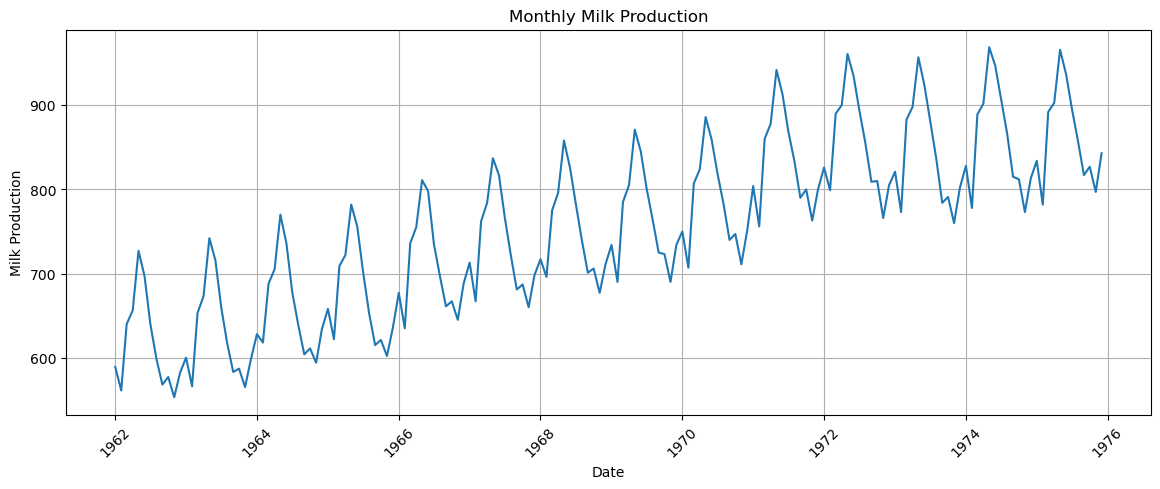

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df['Production'])

plt.title("Monthly Milk Production")
plt.xlabel("Date")
plt.ylabel("Milk Production")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [12]:
print(df.isnull().sum())

Production    0
dtype: int64


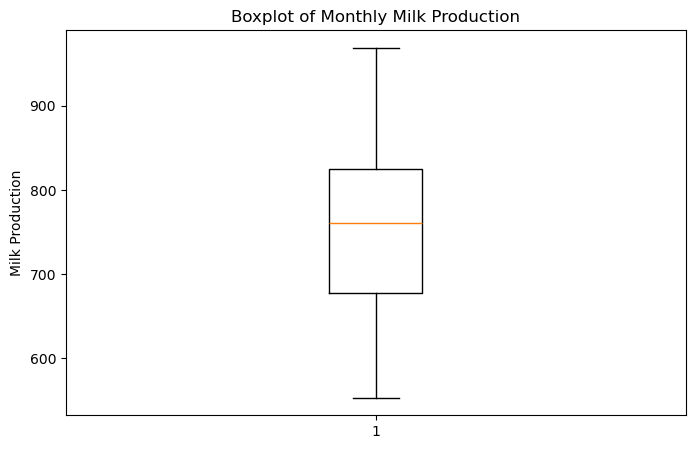

In [13]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['Production'])

plt.title("Boxplot of Monthly Milk Production")
plt.ylabel("Milk Production")

plt.show()

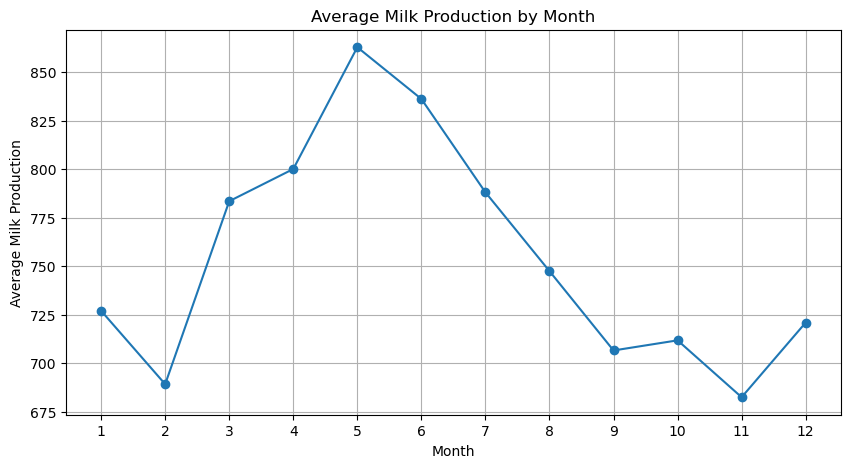

In [16]:
monthly_avg = df.groupby(df.index.month)['Production'].mean()

plt.figure(figsize=(10, 5))

plt.plot(monthly_avg.index, monthly_avg.values, marker='o')

plt.title("Average Milk Production by Month")
plt.xlabel("Month")
plt.ylabel("Average Milk Production")
plt.xticks(range(1, 13))

plt.grid(True)
plt.show()

In [17]:
monthly_avg

Date
1     727.071429
2     689.285714
3     783.500000
4     800.071429
5     862.785714
6     836.142857
7     788.071429
8     747.500000
9     706.642857
10    711.857143
11    682.571429
12    721.000000
Name: Production, dtype: float64

### Monthly Average Production – Seasonality Observations

- The **highest average milk production** is observed in **May**, with an average of **862.79 units**.
- The **lowest average production** occurs in **November**, with an average of **682.57 units**.
- Production generally increases from **January (727.07)** to **May (862.79)**, indicating a strong upward seasonal pattern during the first half of the year.
- After May, production gradually decreases, reaching **706.64 units in September** and **682.57 units in November**.
- Production rises slightly again in **December**, reaching **721.00 units**.
- The difference between the highest and lowest monthly averages is approximately **180.21 units**, indicating noticeable **seasonal variation**.
- Overall, the data suggests a recurring seasonal pattern, with **higher milk production during April–June** and **lower production around October–November**.
- This seasonality should be considered when building the **RNN, LSTM, and GRU forecasting models**, as historical monthly patterns may help improve future predictions.

In [18]:
data = df[['Production']].values

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(data)

In [19]:
window_size = 12

In [20]:
def create_sequences(data, window_size):
    X = []
    y = []

    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

In [21]:
train_size = int(len(scaled_data) * 0.70)
val_size = int(len(scaled_data) * 0.15)

train_data = scaled_data[:train_size]

val_data = scaled_data[train_size:train_size + val_size]

test_data = scaled_data[train_size + val_size:]

In [22]:
X, y = create_sequences(scaled_data, window_size)

In [23]:
train_end = train_size - window_size
val_end = train_end + val_size

X_train = X[:train_end]
y_train = y[:train_end]

X_val = X[train_end:val_end]
y_val = y[train_end:val_end]

X_test = X[val_end:]
y_test = y[val_end:]

In [25]:
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_val = X_val.reshape(
    X_val.shape[0],
    X_val.shape[1],
    1
)

X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

In [26]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (105, 12, 1)
Validation: (25, 12, 1)
Testing: (26, 12, 1)


### Data Reshaping and Sequence Preparation – Observations

- A **12-month window** was used to predict the production for the following month.
- The training dataset contains **105 sequences**, each consisting of **12 time steps and 1 feature**, resulting in a shape of **(105, 12, 1)**.
- The validation dataset contains **25 sequences**, with a shape of **(25, 12, 1)**.
- The testing dataset contains **26 sequences**, with a shape of **(26, 12, 1)**.
- The final input shape **(samples, time steps, features)** is suitable for training **RNN, LSTM, and GRU** models.
- Using the previous **12 months** allows the models to capture potential **annual seasonal patterns** in milk production.
- The chronological split ensures that future observations are not used during model training, which is important for **time series forecasting**.

In [27]:
rnn_model = Sequential([
    SimpleRNN(64, activation='tanh', input_shape=(window_size, 1)),
    Dense(32, activation='relu'),
    Dense(1)
])

rnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 64)                  │           4,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
history_rnn = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0398 - val_loss: 0.0341
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0103 - val_loss: 0.0052
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0068 - val_loss: 0.0218
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0042 - val_loss: 0.0084
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0029 - val_loss: 0.0103
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0025 - val_loss: 0.0051
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0020 - val_loss: 0.0046
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0017 - val_loss: 0.0043
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0015 - val_loss: 0.0038
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0013 - val_loss: 0.0041
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0013 - val_loss: 0.0040
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0012 - val_lo

In [29]:
lstm_model = Sequential([
    LSTM(64, activation='tanh', input_shape=(window_size, 1)),
    Dense(32, activation='relu'),
    Dense(1)
])

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history_lstm = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.1499 - val_loss: 0.2137
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0559 - val_loss: 0.0367
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0286 - val_loss: 0.0361
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0283 - val_loss: 0.0274
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0249 - val_loss: 0.0379
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0248 - val_loss: 0.0257
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0239 - val_loss: 0.0220
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0234 - val_loss: 0.0261
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0227 - val_loss: 0.0243
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0219 - val_loss: 0.0211
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0221 - val_loss: 0.0209
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0213 - val_lo

In [31]:
gru_model = Sequential([
    GRU(64, activation='tanh', input_shape=(window_size, 1)),
    Dense(32, activation='relu'),
    Dense(1)
])

gru_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 64)                  │          12,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history_gru = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0971 - val_loss: 0.0852
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0247 - val_loss: 0.0193
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0242 - val_loss: 0.0187
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0180 - val_loss: 0.0294
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0185 - val_loss: 0.0249
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0171 - val_loss: 0.0194
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0167 - val_loss: 0.0191
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0161 - val_loss: 0.0203
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0158 - val_loss: 0.0188
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0153 - val_loss: 0.0185
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0148 - val_loss: 0.0168
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0145 - val_lo

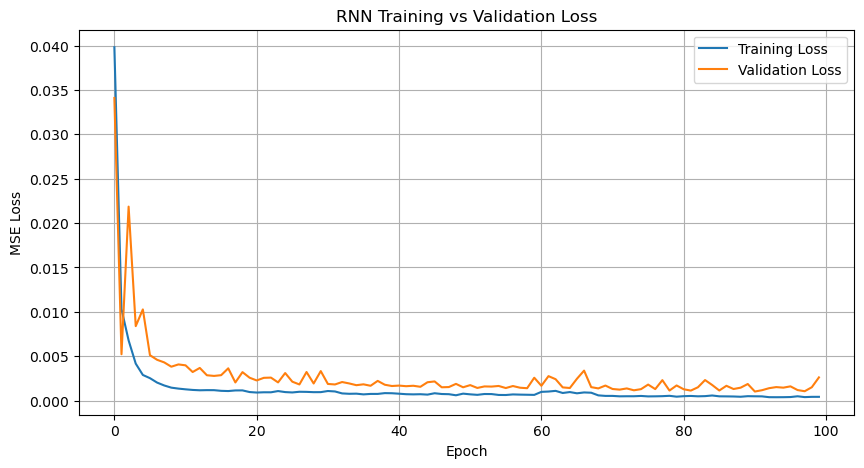

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(history_rnn.history['loss'], label='Training Loss')
plt.plot(history_rnn.history['val_loss'], label='Validation Loss')

plt.title("RNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

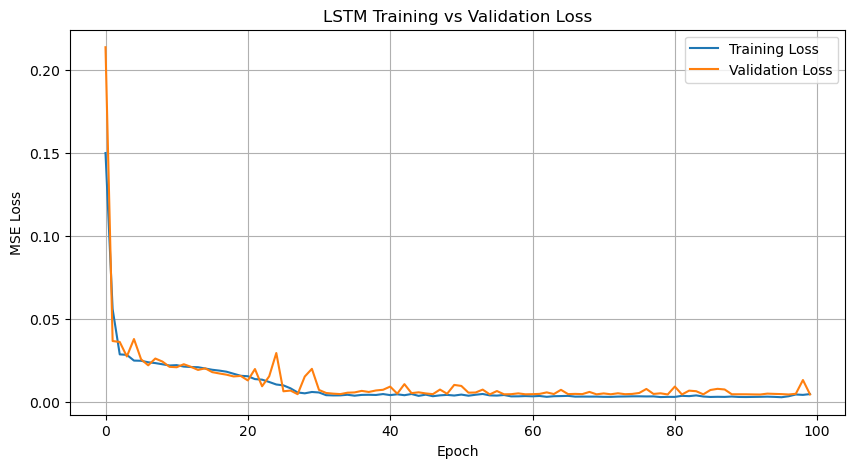

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history['loss'], label='Training Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

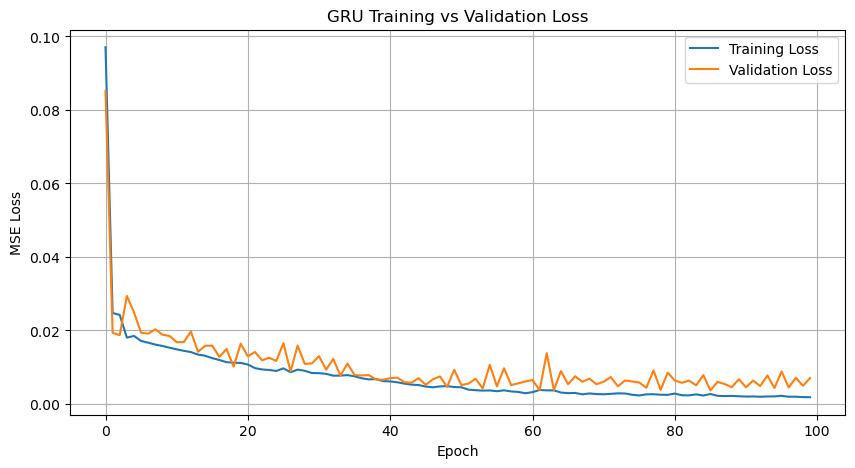

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(history_gru.history['loss'], label='Training Loss')
plt.plot(history_gru.history['val_loss'], label='Validation Loss')

plt.title("GRU Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [36]:
rnn_pred = rnn_model.predict(X_test)
lstm_pred = lstm_model.predict(X_test)
gru_pred = gru_model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step


In [37]:
rnn_pred_original = scaler.inverse_transform(rnn_pred)
lstm_pred_original = scaler.inverse_transform(lstm_pred)
gru_pred_original = scaler.inverse_transform(gru_pred)

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

In [38]:
def calculate_metrics(actual, predicted):

    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return rmse, mae, mape

In [39]:
rnn_metrics = calculate_metrics(
    y_test_original,
    rnn_pred_original
)

lstm_metrics = calculate_metrics(
    y_test_original,
    lstm_pred_original
)

gru_metrics = calculate_metrics(
    y_test_original,
    gru_pred_original
)

In [40]:
results = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],
    'RMSE': [
        rnn_metrics[0],
        lstm_metrics[0],
        gru_metrics[0]
    ],
    'MAE': [
        rnn_metrics[1],
        lstm_metrics[1],
        gru_metrics[1]
    ],
    'MAPE (%)': [
        rnn_metrics[2],
        lstm_metrics[2],
        gru_metrics[2]
    ]
})

results

,Model,RMSE,MAE,MAPE (%)
0,RNN,17.140755,13.764714,1.658180
1,LSTM,26.119013,21.648646,2.574353
2,GRU,32.179881,27.592133,3.264255


### Model Evaluation – Observations

- The **RNN model** achieved the lowest RMSE (**17.14**), MAE (**13.76**), and MAPE (**1.66%**) among the three models.
- The **LSTM model** recorded an RMSE of **26.12**, MAE of **21.65**, and MAPE of **2.57%**.
- The **GRU model** had the highest errors, with an RMSE of **32.18**, MAE of **27.59**, and MAPE of **3.26%**.
- The results indicate that the **RNN produced the closest predictions to the actual milk production values on the test set** for this dataset and model configuration.
- The RNN's MAPE of **1.66%** indicates that its predictions differed from actual production by approximately **1.66% on average** in relative terms.
- Overall, the three models produced reasonably low forecasting errors, but their performance differed considerably despite using the same time-series data.
- Based on the test-set metrics, the **RNN model can be selected for generating the 12-month future forecast**.

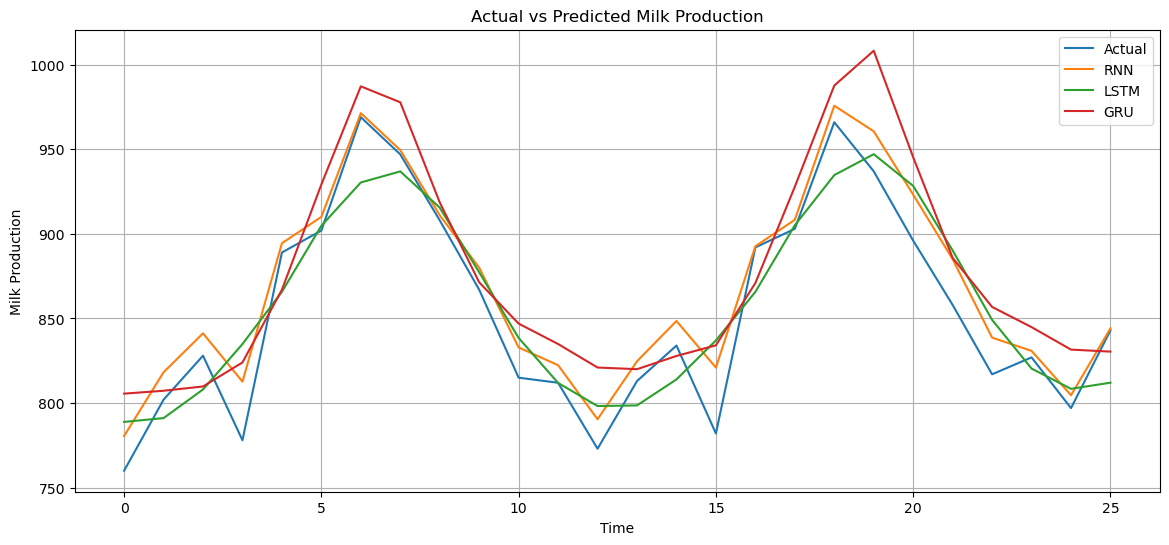

In [41]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test_original,
    label='Actual'
)

plt.plot(
    rnn_pred_original,
    label='RNN'
)

plt.plot(
    lstm_pred_original,
    label='LSTM'
)

plt.plot(
    gru_pred_original,
    label='GRU'
)

plt.title("Actual vs Predicted Milk Production")
plt.xlabel("Time")
plt.ylabel("Milk Production")

plt.legend()
plt.grid(True)

plt.show()

In [42]:
best_model = rnn_model

In [43]:
last_sequence = scaled_data[-window_size:].reshape(1, window_size, 1)

In [44]:
future_predictions = []

current_sequence = last_sequence.copy()

for i in range(12):

    next_prediction = best_model.predict(
        current_sequence,
        verbose=0
    )

    future_predictions.append(next_prediction[0, 0])

    current_sequence = np.append(
        current_sequence[:, 1:, :],
        next_prediction.reshape(1, 1, 1),
        axis=1
    )

In [45]:
future_predictions = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)
)

In [46]:
last_date = df.index[-1]

future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=12,
    freq='MS'
)

In [47]:
forecast_df = pd.DataFrame({
    'Month': future_dates,
    'Forecasted Milk Production': future_predictions.flatten()
})

forecast_df

,Month,Forecasted Milk Production
0,1976-01-01,867.628296
1,1976-02-01,849.802917
2,1976-03-01,927.620300
3,1976-04-01,938.301331
4,1976-05-01,979.441467
5,1976-06-01,954.979492
6,1976-07-01,924.860046
7,1976-08-01,894.442505
8,1976-09-01,867.289307
9,1976-10-01,866.206848


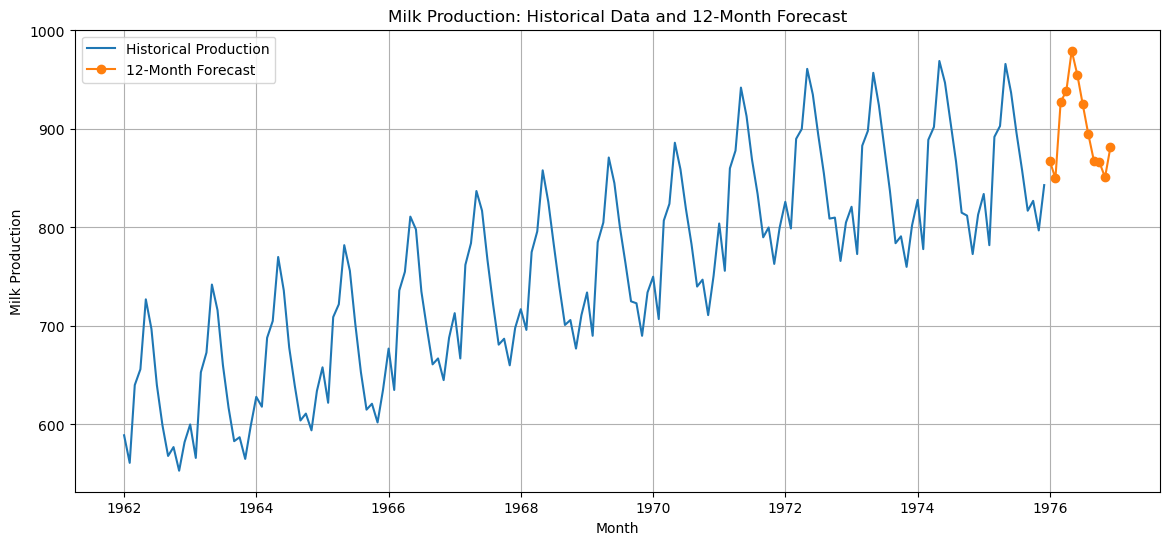

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df['Production'],
    label='Historical Production'
)

plt.plot(
    future_dates,
    future_predictions,
    marker='o',
    label='12-Month Forecast'
)

plt.title("Milk Production: Historical Data and 12-Month Forecast")
plt.xlabel("Month")
plt.ylabel("Milk Production")

plt.legend()
plt.grid(True)

plt.show()

## Conclusion

- The study successfully developed and evaluated three deep learning models—**RNN, LSTM, and GRU**—for forecasting monthly milk production.
- Exploratory analysis revealed **clear seasonal variations** in milk production, with higher average production during **April–June** and lower production around **October–November**.
- A **12-month time window** was used to capture annual seasonal patterns and provide input to the deep learning models.
- Among the three models, the **RNN achieved the lowest RMSE (17.14), MAE (13.76), and MAPE (1.66%)** on the test dataset.
- The LSTM and GRU models produced higher forecasting errors, with MAPE values of **2.57%** and **3.26%**, respectively.
- Based on the test-set performance, the **RNN model was selected for forecasting the next 12 months of milk production**.
- The forecast can support the dairy business in **production planning, inventory management, workforce allocation, storage planning, and supply-chain management**.
- Overall, the analysis demonstrates that **deep learning-based time series models can effectively capture patterns in historical milk production and provide useful forecasts for operational decision-making**.